# Compare firing rate between spike types

This notebook compares firing rate between the specified spike types in a given sleep stage.

**Note:** This notebook uses the output of the [Describe sleep stage intervals per cell](Describe%20sleep%20stage%20intervals%20per%20cell.ipynb) notebook, you need to run that first.

## Initialization - don't change

In [1]:
import sys
sys.path.append('..')

from pathlib import Path

from tqdm import tqdm

from workflows.run_util.io import collect_results_from_table
from param_classes.workflows.episode_analysis import GroupwiseComparisonParams
from workflows.episode_analysis import run_spike_type_comparison, create_groups

params = GroupwiseComparisonParams()

## Color settings

In [ ]:
params.palette = {
    'episode': {
        'awake': '#0000ff',
        'theta': '#ff0000',
        'sw': '#00ff00',
        'spdl': '#ffa500',
        'delta': '#800080'
    },
    'spike_type': {
        'AIS-AP': 'celltype',
        'UNKNOWN': '#adadad',
        'RA-AP': '#00ff00'
    },
    'celltype': {
        'PYR_L2-3': '#803300ff',
        'PYR_L4-6': '#502d16ff',
        'RSI_L2-3': '#ff48a3ff',
        'RSI_L4-6': '#800080ff',
        'FSI_L2-3': '#d54500ff',
        'FSI_L4-6': '#7a0000ff'
    }
}

## Data settings

Set the base path of the directory where the sleep stage description results have been saved.
> It needs to be the same structure as the `raw_data` directory.

In [3]:
params.data.results.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\EpisodeAnalysis'
params.data.results.extension = 'xlsx'
params.data.results.suffix = 'episodes'

## Input-output settings

Set the Excel table containing the cell attributes, grouping and selector information.

In [4]:
params.input = {
    'mode': 'table',
    'table_path': 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\data_invivo.xlsx',
    'select_rules': [
        {'selected': 1}
    ]
}

Set the output base directory path. All results of this analysis (cellwise aggregated tables, grouped results, figures, statistics) is going to saved there.

In [5]:
params.output.figures.dpi = 100
params.output.figures.as_png = True
params.output.figures.as_svg = True

## Analysis parameters

In [6]:
params.analysis.episodes = ['sw', 'theta', 'spdl', 'delta']
params.analysis.spike_types = ['AIS-AP', 'RA-AP']
params.analysis.suffix = 'episodes'

## Grouping parameters

In [7]:
params.grouping.aggregation = 'mean'

## Run analysis

Collect input files according to the table.

In [8]:
input_files = collect_results_from_table(params.data.results, params.input)
print(f"{len(input_files)} files selected for analysis.")

6 files selected for analysis.


Run comparison for each groups.

Process groups:   0%|          | 0/2 [00:00<?, ?it/s]

         name     group episode  ratio spike_type  frequency
0   B4_d2t1c1  FSI_L2-3      sw    1.0     AIS-AP  26.650070
1  J21_d2t1c3  FSI_L2-3      sw    1.0     AIS-AP  30.465525
2  J47_d2t1c4  FSI_L2-3      sw    1.0     AIS-AP  57.836306
3   B4_d2t1c1  FSI_L2-3      sw    1.0      RA-AP   0.737287
4  J21_d2t1c3  FSI_L2-3      sw    1.0      RA-AP   0.720420
5  J47_d2t1c4  FSI_L2-3      sw    1.0      RA-AP   1.874931
         name     group episode  ratio spike_type  frequency
0   B4_d2t1c1  FSI_L2-3   theta    1.0     AIS-AP  21.547660
1  J21_d2t1c3  FSI_L2-3   theta    NaN     AIS-AP        NaN
2  J47_d2t1c4  FSI_L2-3   theta    NaN     AIS-AP        NaN
3   B4_d2t1c1  FSI_L2-3   theta    1.0      RA-AP   6.074937
4  J21_d2t1c3  FSI_L2-3   theta    NaN      RA-AP        NaN
5  J47_d2t1c4  FSI_L2-3   theta    NaN      RA-AP        NaN


c:\Projects\RaAp\notebooks\..\workflows\episode_analysis.py:600: RuntimeWarning: Mean of empty slice
  ax.set_title(f"{episode} ratio: {np.nanmean(subset['ratio']):.2f}")
Process groups:   0%|          | 0/2 [00:00<?, ?it/s]

         name     group episode     ratio spike_type  frequency
0   B4_d2t1c1  FSI_L2-3    spdl  0.347826     AIS-AP  35.177112
1  J21_d2t1c3  FSI_L2-3    spdl  0.400000     AIS-AP  50.574515
2  J47_d2t1c4  FSI_L2-3    spdl  0.494118     AIS-AP  89.382905
3   B4_d2t1c1  FSI_L2-3    spdl  0.347826      RA-AP   3.568073
4  J21_d2t1c3  FSI_L2-3    spdl  0.400000      RA-AP   3.514915
5  J47_d2t1c4  FSI_L2-3    spdl  0.494118      RA-AP   5.505595


KeyError: 'spdl'

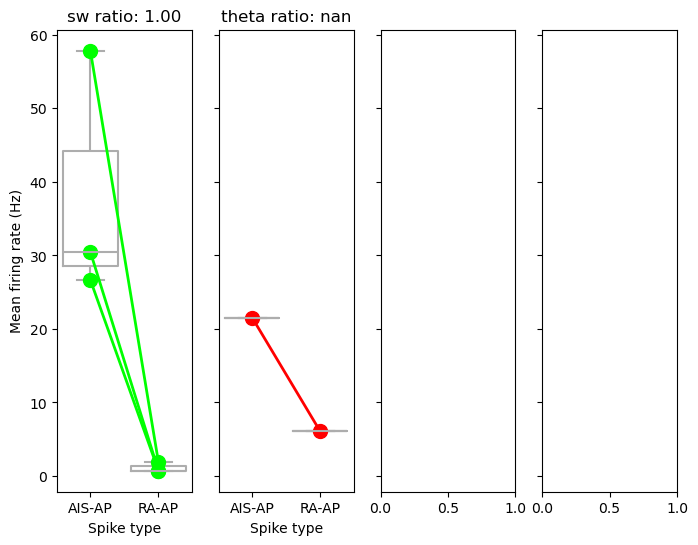

In [9]:
groups = create_groups(input_files)
run_spike_type_comparison(groups, params)